In [ ]:
!pip install -q git+https://github.com/sparc4-dev/astropop
# !pip install -q ipympl

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 36.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 56.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 368.5/368.5 kB 31.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 6.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 60.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 888.9/888.9 kB 53.9 MB/s eta 0:00:00


In [ ]:
import numpy as np
from matplotlib import pyplot as plt
from astropy.table import Table
from astropy.modeling import fitting, Fittable1DModel, Parameter
from astropy import units

# from google.colab import output
# output.enable_custom_widget_manager()

# %matplotlib notebook
%matplotlib inline
# %matplotlib ipympl

# Polarimetry Normalization Problem

Ordinary and extraodinary beams from Savart or Wollaston polarimeters may need a normalization in the flux due to the possibility that the instrument do not respond with the same efficiency for both polarization directions. Also, Savart prism has different optical paths for both beams, making 2 different focal planes and generating 2 different PSFs for both beams.

The ideal relative flux $z_{_i}$ for the beams in each plate position is described as:

$$
z_{i} = \frac{F_{o,i} - F_{e,i}}{F_{o,i} + F_{e,i}}
$$

where $F_{o,i}$ is the flux of ordinary beam and $F_{e,i}$ is the flux of extraordinary beam. But, with this response problem, a $k$ factor is used for propper normalization. This equation turns into:

$$
z_{i} = \frac{F_{o,i} - F_{e,i} \cdot k}{F_{o,i} - F_{e,i} \cdot k}
$$

where **Claudia - isto aqui é valido no caso de lamina de meia onda e com um ciclo completo. Ver tb [Lima et al. 2021](https://ui.adsabs.harvard.edu/abs/2021AJ....161..225L/abstract)**

Half-Wave
$$
k = \sum_i^n{\frac{F_{o,i}}{F_{e,i}}}
$$

Quarter-Wave
$$
k = \left(\sum_i^n{\frac{F_{o,i}}{F_{e,i}}}\right)\cdot\frac{1-0.5\cdot{q}}{1+0.5\cdot{q}}
$$

## Stokes Parameters

To determine the Stokes parameters, we can use 2 methods, described in [Campagnolo (2019)](https://ui.adsabs.harvard.edu/abs/2019PASP..131b4501N), [Magalhães (1984)](https://ui.adsabs.harvard.edu/abs/1984PASP...96..383M) and [Rodrigues (1998)](https://ui.adsabs.harvard.edu/abs/1998A&A...335..979R).

After determine Q and U parameters, the **linear** polarization level and position angle are computed as:

$$
P = \sqrt{Q^2 + U^2}
$$

$$
\Theta = \frac{1}{2}\arctan{\left(\frac{U}{Q}\right)}
$$

### MBR84 Method

[Magalhães (1984)](https://ui.adsabs.harvard.edu/abs/1984PASP...96..383M) determine Q and U stokes parameters using the equations:

#### Half-wave Retarder

$$
Q = \frac{2}{n}\sum_{i=1}^{n} z_i \cos{4\Psi_i}
$$

$$
U = \frac{2}{n}\sum_{i=1}^{n} z_i \sin{4\Psi_i}
$$

#### Quarter-wave Retarder

**[Claudia] [Rodrigues et al. (1998)](https://ui.adsabs.harvard.edu/abs/1998A%26A...335..979R/abstract) determine Q, U, and V Stokes parameters using the equations:**

$$
Q = \frac{1}{3}\sum_{i=1}^{8}z_i\cos^2{2\Psi_i}
$$

$$
U = \sum_{i=1}^{8}z_i\sin{2\Psi_i}\cos2{\Psi_i}
$$

$$
V = -\frac{1}{4}\sum_{i=1}^{8}z_i\sin{2\Psi_i}
$$

### SLS Method

As pointed by [Campagnolo (2019)](https://ui.adsabs.harvard.edu/abs/2019PASP..131b4501N), fitting the model that describes the relative flux at each waveplate position to the points may give a more robust result. The models are:

#### Half-wave Retarder
$$
z_i = Q\cos{4\Psi_i} + U\sin{4\Psi_i}
$$

#### Quarter-wave Retarder
$$
z_i = Q\cos^2{2\Psi_i} + U\sin{2\Psi_i}\cos{2\Psi_i} - V\sin{2\Psi_i}
$$

## Simulating Data

Considering that $z_i$ is the percentual relative difference of fluxes between ordinary and extraordinary fluxes, and the flux is split between the two beams, the flux in each beam is described as:

$$
F_{o,i} = F_i \cdot \frac{1 + z_i}{2}
$$

$$
F_{e,i} = F_i \cdot \frac{1 - z_i}{2}
$$

So, computing the $z_i$ for given parameters allow to compute the beam fluxes for each plate position, no matter the retarder used.

For normalization simulation, we just need to divide one of the beams by $k$, in our case $F_{e,i}$, to match the normalization equation above.

In [ ]:
# Define the models
# On both models, float means radian angle and quantities are accepted


class ConstModel(Fittable1DModel):
    h = Parameter(default=0)

    @staticmethod
    def evaluate(psi, h):
        return h

class HalfWaveModel(Fittable1DModel):
    q = Parameter(default=0)
    u = Parameter(default=0)

    @staticmethod
    def evaluate(psi, q, u):
        return q*np.cos(4*psi) + u*np.sin(4*psi)


class QuarterWaveModel(Fittable1DModel):
    q = Parameter(default=0)
    u = Parameter(default=0)
    v = Parameter(default=0)

    @staticmethod
    def evaluate(psi, q, u, v):
        psi2 = 2*psi
        return q*(np.cos(psi2)**2) + u*np.sin(psi2)*np.cos(psi2) - v*np.sin(psi2)


def get_q_u(p, theta):
    """Get Q and U for linear polarimetry."""
    q = p*np.cos(2*theta)
    u = p*np.sin(2*theta)
    return q, u


def get_zi(psi, q, u, v=None):
    """Get z(i) fluxes for each position."""
    if v is None:
        return HalfWaveModel.evaluate(psi, q, u)
    else:
        return QuarterWaveModel.evaluate(psi, q, u, v)

def get_flux_oe(flux, psi, k, q, u, v=None):
    """Get ordinary and extraordinary fluxes."""
    zi = get_zi(psi, q, u, v)
    fo = flux*(1+zi)/2
    fe = flux*(1-zi)/2
    return fo, fe/k

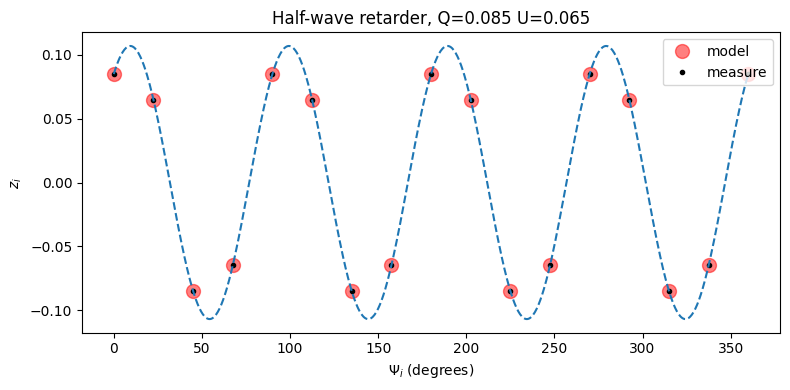

In [ ]:
# Half-wave
p = 0.1
theta = 15*units.degree
q, u = 0.085, 0.065

pos = np.arange(0, 360.5, 22.5)*units.degree
line = np.arange(0, 360.5, 0.5)*units.degree

zi_predicted = get_zi(pos, q, u)
fo, fe = get_flux_oe(1e5, pos, 1.0, q, u)
zi_measure = (fo - fe)/(fo + fe)

plt.figure(figsize=(8, 4))
plt.plot(pos, zi_predicted, 'ro', alpha=0.5, ms=10, label='model')
plt.plot(pos, zi_measure, 'k.', label='measure')
plt.plot(line, get_zi(line, q, u), '--')
plt.xlabel(r'$\Psi_i$ (degrees)')
plt.ylabel(r'$z_i$')
plt.title(f'Half-wave retarder, Q={q:.3f} U={u:.3f}')
plt.legend()
plt.tight_layout()
plt.show()

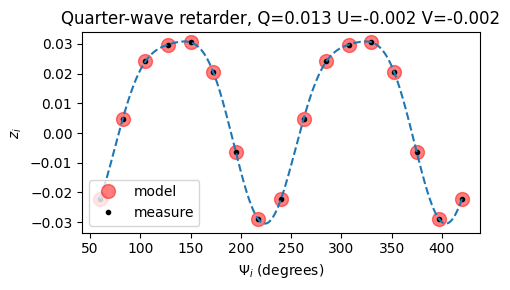

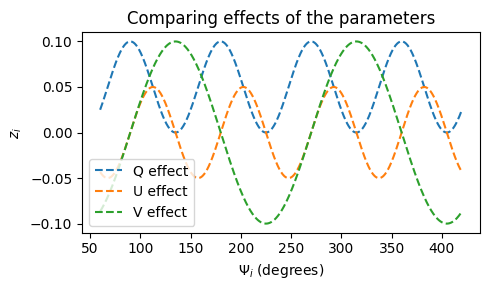

In [ ]:
# Quarter-wave
q = 0.0130
u = -0.0021
v = 0.03044

pos = (np.arange(0, 360.5, 22.5) + 60)*units.degree
line = (np.arange(0, 360.5, 0.5) + 60)*units.degree

zi_predicted = get_zi(pos, q, u, v)
fo, fe = get_flux_oe(1e5, pos, 1.0, q, u, v)
zi_measure = (fo - fe)/(fo + fe)

plt.figure(figsize=(5, 3))
plt.plot(pos, zi_predicted, 'ro', alpha=0.5, ms=10, label='model')
plt.plot(pos, zi_measure, 'k.', label='measure')
plt.plot(line, get_zi(line, q, u, v), '--')
plt.xlabel(r'$\Psi_i$ (degrees)')
plt.ylabel(r'$z_i$')
plt.title(f'Quarter-wave retarder, Q={q:.3f} U={u:.3f} V={u:.3f}')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 3))
plt.plot(line, get_zi(line, 0.1, 0, 0), '--', label=f'Q effect')
plt.plot(line, get_zi(line, 0, 0.1, 0), '--', label=f'U effect')
plt.plot(line, get_zi(line, 0, 0, 0.1), '--', label=f'V effect')
plt.title('Comparing effects of the parameters')
plt.xlabel(r'$\Psi_i$ (degrees)')
plt.ylabel(r'$z_i$')
plt.legend()
plt.tight_layout()
plt.show()

All our models looks fine! The quarter-wave model is compatible with the sample graph from [Claudia's page](http://www.das.inpe.br/~claudia.rodrigues/). The half-wave model gives the expected result.
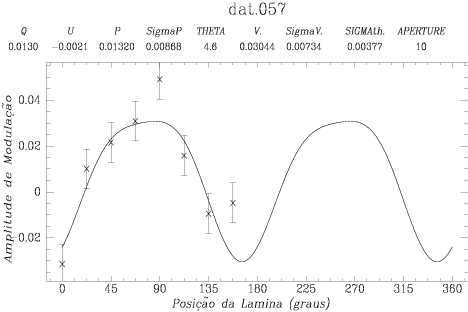

# Effect of Normalization in the Models


## Half-Wave

When simulate the data without any difference between ordinary and extraordinary beams, the model is vertically centered on the 0. But, we expect that the difference in efficiency of the detector displaces the graph vertically. But the relation between this displacement and the normalization will be investigated here.

Let's simulate some data with $k$ varying from 0.8 to 1.2, a range that probably covers pratical applications.

Expected P=0.0961769
Expected 2*P=0.1923538
k=0.80 amplitude=0.1900008 mean=-0.11060
k=0.85 amplitude=0.1911009 mean=-0.08071
k=0.90 amplitude=0.1918259 mean=-0.05239
k=0.95 amplitude=0.1922285 mean=-0.02552
k=1.00 amplitude=0.1923538 mean=0.00000
k=1.05 amplitude=0.1922405 mean=0.02428
k=1.10 amplitude=0.1919217 mean=0.04740
k=1.15 amplitude=0.1914262 mean=0.06945
k=1.20 amplitude=0.1907787 mean=0.09049
k=1.25 amplitude=0.1900008 mean=0.11060


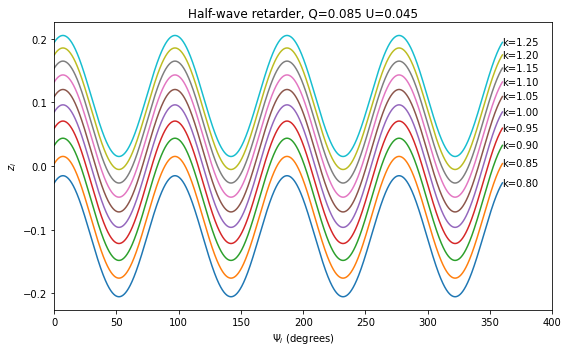

In [ ]:
f = 1e5
q = 0.085
u = 0.045
line = np.arange(0, 360, 0.005)*units.degree
pos = np.arange(0, 360, 22.5)*units.degree

print(f'Expected P={np.hypot(q, u):.7f}')
print(f'Expected 2*P={2*np.hypot(q, u):.7f}')

flux = {}
z = {}
mean = {}
amplitude = {}

plt.figure(figsize=(8, 5))
for k in np.arange(0.80, 1.3, 0.05):
    fo, fe = get_flux_oe(f, line, k, q, u)
    flux[k] = (fo, fe)
    zi = (fo - fe)/(fo + fe)
    z[k] = zi
    plt.plot(line, zi, '-')
    plt.annotate(f'k={k:.2f}', (line[-1].value, zi[-1]), va='center')
    mean[k] = np.mean(zi)
    amplitude[k] = np.max(zi)-np.min(zi)
    print(f'k={k:.2f} amplitude={amplitude[k]:.7f} mean={mean[k]:.5f}')

plt.xlim(0, 400)
plt.xlabel(r'$\Psi_i$ (degrees)')
plt.ylabel(r'$z_i$')
plt.title(f'Half-wave retarder, Q={q:.3f} U={u:.3f}')
plt.tight_layout()
plt.show()

There are 2 main effects noticed:
- The expected vertical displacement between the plots. Values of $k$ lower then 1.0 displaces all the plot down. Values of $k$ higher then 1 rises the plot.
- The amplitude of the plots decreases as $k$ goes far from 1.0. With $k=1$, the amplitude matches 2 times the polarization level $P$, as expected.

So, plotting the results as function of k, we obtain:

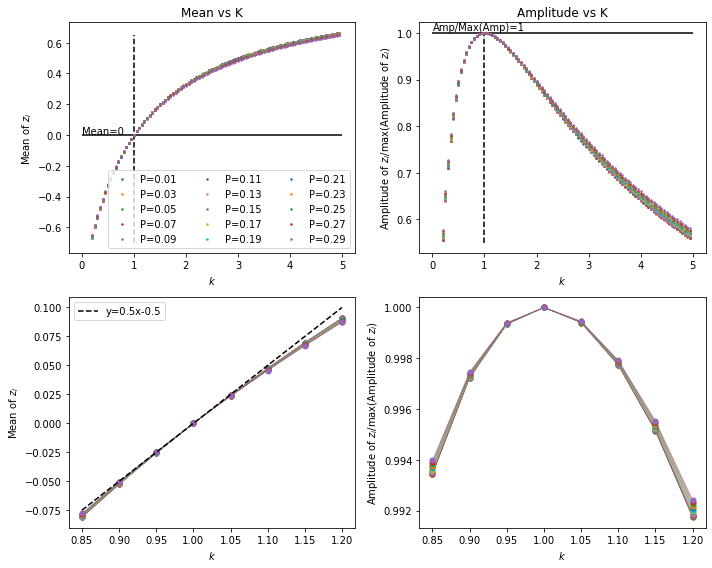

In [ ]:
f = 1e5
line = np.arange(0, 360, 0.005)*units.degree

fig, ax = plt.subplots(2, 2, figsize=(10, 8))

# do it for several q
ks = np.arange(0.2, 5, 0.05)
for i, p in enumerate(np.arange(0.01, 0.3, 0.02)):
    q, u = get_q_u(p, 45*units.degree)
    means = []
    amplitudes = []
    for k in ks:
        fo, fe = get_flux_oe(f, line, k, q, u)
        zi = (fo - fe)/(fo + fe)
        means.append(np.mean(zi))
        amplitudes.append(np.max(zi) - np.min(zi))
    means = np.array(means)
    amplitudes = np.array(amplitudes)

    ax[0][0].plot(ks, means, '.', ms=3, label=f'P={p:.2f}', color=f'C{i}')
    ax[0][1].plot(ks, amplitudes/np.max(amplitudes), '.', ms=3, label=f'P={p:.2f}', color=f'C{i}')

    filt = np.where(np.logical_and(ks <= 1.2, ks >=0.8))
    ax[1][0].plot(ks[filt], means[filt], '.-', lw=0.5, ms=10, color=f'C{i}')
    ax[1][1].plot(ks[filt], amplitudes[filt]/np.max(amplitudes), '.-', lw=0.5, ms=10, color=f'C{i}')

ax[0][0].hlines(0, 0, 5)
ax[0][0].vlines(1.0, -0.7, 0.65, linestyles='dashed')
ax[0][0].annotate('Mean=0', (0, 0.005))
ax[0][0].set_title('Mean vs K')

ax[0][1].hlines(1, 0, 5)
ax[0][1].annotate('Amp/Max(Amp)=1', (0, 1.005))
ax[0][1].vlines(1.0, 0.55, 1.0, linestyles='dashed')
ax[0][1].set_title('Amplitude vs K')

ax[1][0].plot([0.85, 1.2], [-0.075, 0.1], 'k--', label='y=0.5x-0.5')

for i in (0, 1):
    ax[i][0].set_xlabel(r'$k$')
    ax[i][0].set_ylabel(r'Mean of $z_i$')
    ax[i][1].set_xlabel(r'$k$')
    ax[i][1].set_ylabel(r'Amplitude of $z_i$/max(Amplitude of $z_i$)')

ax[0][0].legend(ncol=3)
ax[1][0].legend()

plt.tight_layout()
plt.show()

Even using a large range of polarization levels (from 1 to 29%), the results are very similar. The effect slightly grows with the polarization level.

Also, for a very small range of $k$, from 0.95 to 1.05, the linear trend of $y=0.5x-0.5$ seems to work fine for every polarization level, but the discrepancy grows with $k$.

### Fitting models without normalize

Let's simply fitting the half-wave model with a constant $H$ parameter added to displace the graph vertically.

To simplify the analysis, let's use $Q=0$ and $U=0.1$. With this, we do not need to recompute $P$, since it will allways be equal to $U$.

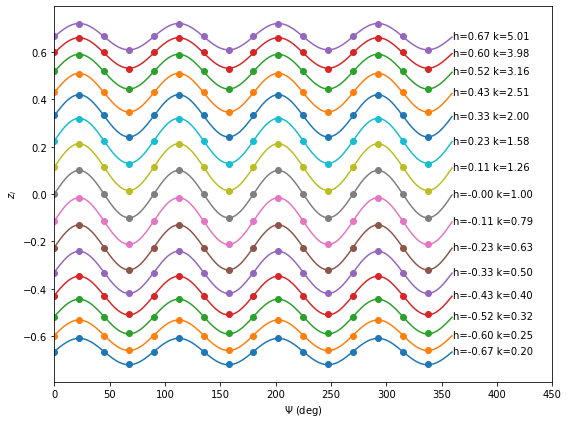

In [ ]:
f = 1e5
pos = np.radians(np.arange(0, 360, 22.5)*units.degree).value
line = np.arange(0, 360, 0.5)*units.degree
q, u = 0, 0.1

t = Table(names=['k', 'q_fit', 'u_fit', 'h_fit'],
          dtype=['f4', 'f4', 'f4', 'f4'])

plt.figure(figsize=(8, 6))
for i, kexp in enumerate(np.arange(-0.7, 0.8, 0.1)):
    k = 10**kexp
    fo, fe = get_flux_oe(f, pos, k, q, u)
    zi = (fo - fe)/(fo + fe)
    fitter = fitting.LevMarLSQFitter()
    mod_fit = fitter(HalfWaveModel()+ConstModel(), pos, zi)
    t.add_row([k, *mod_fit.parameters])
    plt.plot(line, mod_fit(line), '-', color=f'C{i}')
    plt.plot(np.degrees(pos), zi, 'o', color=f'C{i}')
    h = mod_fit.parameters[-1]
    plt.annotate(f'h={h:.2f} k={k:.2f}', (360, h), va='center')

plt.xlim(0, 450)
plt.xlabel(r'$\Psi$ (deg)')
plt.ylabel(r'$z_i$')
plt.tight_layout()
plt.show()

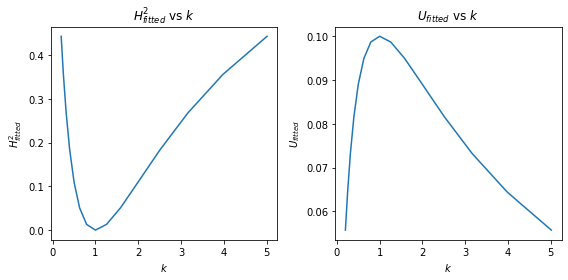

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))

ax[0].plot(t['k'], t['h_fit']**2)
ax[0].set_title(r'$H_{fitted}^2$ vs $k$')
ax[0].set_xlabel(r'$k$')
ax[0].set_ylabel(r'$H_{fitted}^2$')

ax[1].plot(t['k'], t['u_fit'])
ax[1].set_title(r'$U_{fitted}$ vs $k$')
ax[1].set_xlabel(r'$k$')
ax[1].set_ylabel(r'$U_{fitted}$')

plt.tight_layout()
plt.show()

So, as expected, the exact same trends observed in mean and amplitude of the graphics above are observed here too, in $H$, that is equivalent to the mean, and the $U$ (same as $P$ here), that is correlated to the amplitude.

### Reconstructing and Measuring the Polarization

Let's test the algorithm that measure the polarization, including an estimation of the efficiency correction. Let's try an iterative loop that minimize the fitted $H^2$.

In [ ]:
from numpy.core.fromnumeric import nonzero
from astropop.math import qfloat
from scipy.optimize import minimize

from astropy.stats import sigma_clip

class LinearPolFitter:

    def __init__(self, pos, fo, fe, outlier=False):
        self.pos = pos
        self.fo = fo
        self.fe = fe
        self.outlier = outlier

    def fit_model(self, k):
        zi = (self.fo - self.fe*k)/(self.fo + self.fe*k)

        zi, zi_err = zi.nominal, zi.uncertainty
        if self.outlier:
            zi[4] *= np.random.uniform(0.5, 1.5)
            zi_err[4] *= 50
            fitter = fitting.FittingWithOutlierRemoval(fitting.LevMarLSQFitter(),
                                                       sigma_clip, niter=3, sigma=3.0)
            mod_fit, mask = fitter(HalfWaveModel()+ConstModel(), self.pos, zi)
        else:
            fitter = fitting.LevMarLSQFitter()
            mod_fit = fitter(HalfWaveModel()+ConstModel(), self.pos, zi)
        self.params = {n: i for n, i in zip(mod_fit.param_names,
                                            mod_fit.parameters)}
        return self.params['h_1']**2

    def optimize(self):
        res = minimize(self.fit_model, [1.0])
        return res.x

In [ ]:
f = 1e8

t = Table(names=['k', 'k_fit', 'k_calc',
                 'q', 'q_fit', 'q_fit_calc',
                 'u', 'u_fit', 'u_fit_calc'],
          dtype=['f4']*9)

for n in range(400):
    if not n % 20:
        print(n)
    q = np.random.uniform(-0.15, 0.15)
    u = np.random.uniform(-0.15, 0.15)
    k = np.random.uniform(0.5, 2)

    fo, fe = get_flux_oe(f, pos, k, q, u)
    pos = np.radians(np.arange(0, 360, 22.5)*units.degree).value

    fo_err = np.sqrt(fo)
    fe_err = np.sqrt(fe)

    fo = qfloat(np.random.poisson(fo), uncertainty=fo_err)
    fe = qfloat(np.random.poisson(fe), uncertainty=fe_err)

    pol = LinearPolFitter(pos, fo, fe)
    k_fit = pol.optimize()
    k_calc = np.sum(fo.nominal)/np.sum(fe.nominal)

    pol.fit_model(k_fit)
    fit_params = list(pol.params.values())
    pol.fit_model(k_calc)
    calc_params = list(pol.params.values())

    t.add_row([k, k_fit, k_calc,
               q, fit_params[0], calc_params[0],
               u, fit_params[1], calc_params[1]])

0
20
40
60
80
100
120
140
160
180
200
220
240
260
280
300
320
340
360
380


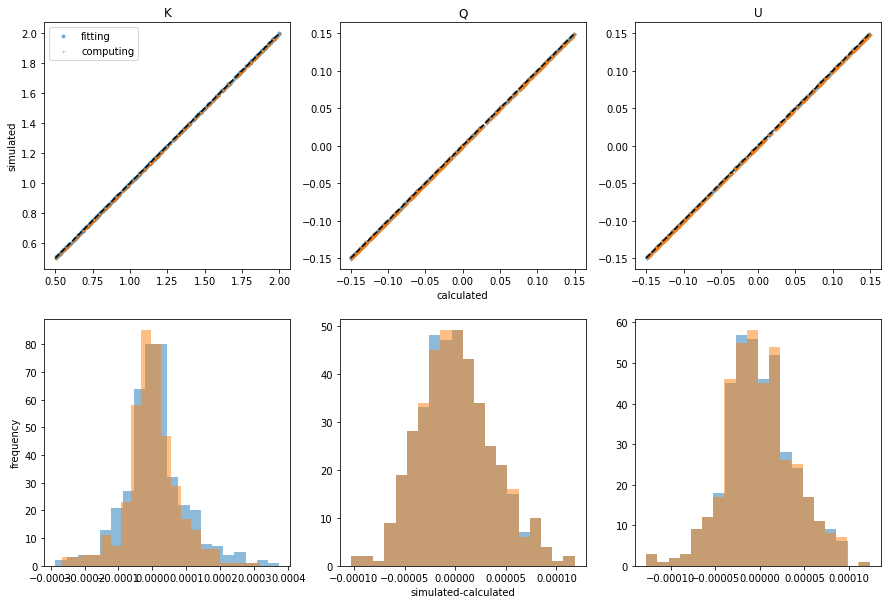

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(15, 10))

ax[0][0].plot(t['k'], t['k_fit'], 'o', ms=3, color='C0', alpha=0.5, label='fitting')
ax[0][0].plot(t['k'], t['k_calc'], '+', ms=3, color='C1', alpha=0.5, label='computing')
ax[0][0].plot([0.5, 2], [0.5, 2], 'k--')
ax[0][0].set_title('K')
ax[0][0].set_ylabel('simulated')
ax[0][0].legend()

ax[1][0].hist(t['k']-t['k_fit'], bins=20, color='C0', alpha=0.5)
ax[1][0].hist(t['k']-t['k_calc'], bins=20, color='C1', alpha=0.5)
ax[1][0].set_ylabel('frequency')

ax[0][1].plot(t['q'], t['q_fit'], 'o', ms=3, color='C0', alpha=0.5)
ax[0][1].plot(t['q'], t['q_fit_calc'], '+', ms=5, color='C1', alpha=0.5)
ax[0][1].plot([-0.15, 0.15], [-0.15, 0.15], 'k--')
ax[0][1].set_xlabel('calculated')
ax[0][1].set_title('Q')

ax[1][1].hist(t['q']-t['q_fit'], bins=20, color='C0', alpha=0.5)
ax[1][1].hist(t['q']-t['q_fit_calc'], bins=20, color='C1', alpha=0.5)
ax[1][1].set_xlabel('simulated-calculated')

ax[0][2].plot(t['u'], t['u_fit'], 'o', ms=3, color='C0', alpha=0.5)
ax[0][2].plot(t['u'], t['u_fit_calc'], '+', ms=5, color='C1', alpha=0.5)
ax[0][2].plot([-0.15, 0.15], [-0.15, 0.15], 'k--')
ax[0][2].set_title('U')

ax[1][2].hist(t['u']-t['u_fit'], bins=20, color='C0', alpha=0.5)
ax[1][2].hist(t['u']-t['u_fit_calc'], bins=20, color='C1', alpha=0.5)

plt.show()

In [ ]:
f = 1e8

t = Table(names=['k', 'k_fit', 'k_calc',
                 'q', 'q_fit', 'q_fit_calc',
                 'u', 'u_fit', 'u_fit_calc'],
          dtype=['f4']*9)

for n in range(400):
    if not n % 20:
        print(n)
    q = np.random.uniform(-0.15, 0.15)
    u = np.random.uniform(-0.15, 0.15)
    k = np.random.uniform(0.5, 2)

    fo, fe = get_flux_oe(f, pos, k, q, u)
    pos = np.radians(np.arange(0, 360, 22.5)*units.degree).value

    fo_err = np.sqrt(fo)
    fe_err = np.sqrt(fe)

    fo = qfloat(np.random.poisson(fo), uncertainty=fo_err)
    fe = qfloat(np.random.poisson(fe), uncertainty=fe_err)

    pol = LinearPolFitter(pos, fo, fe, outlier=True)
    k_fit = pol.optimize()
    k_calc = np.sum(fo.nominal)/np.sum(fe.nominal)

    pol.fit_model(k_fit)
    fit_params = list(pol.params.values())
    pol.fit_model(k_calc)
    calc_params = list(pol.params.values())

    t.add_row([k, k_fit, k_calc,
               q, fit_params[0], calc_params[0],
               u, fit_params[1], calc_params[1]])

0


/usr/local/lib/python3.7/dist-packages/scipy/optimize/optimize.py:1058: RuntimeWarning: divide by zero encountered in double_scalars
  rhok = 1.0 / (numpy.dot(yk, sk))


20
40
60
80
100
120


/usr/local/lib/python3.7/dist-packages/scipy/optimize/optimize.py:1058: RuntimeWarning: divide by zero encountered in double_scalars
  rhok = 1.0 / (numpy.dot(yk, sk))


140
160
180


/usr/local/lib/python3.7/dist-packages/scipy/optimize/optimize.py:1058: RuntimeWarning: divide by zero encountered in double_scalars
  rhok = 1.0 / (numpy.dot(yk, sk))


200
220
240
260
280
300
320
340
360
380


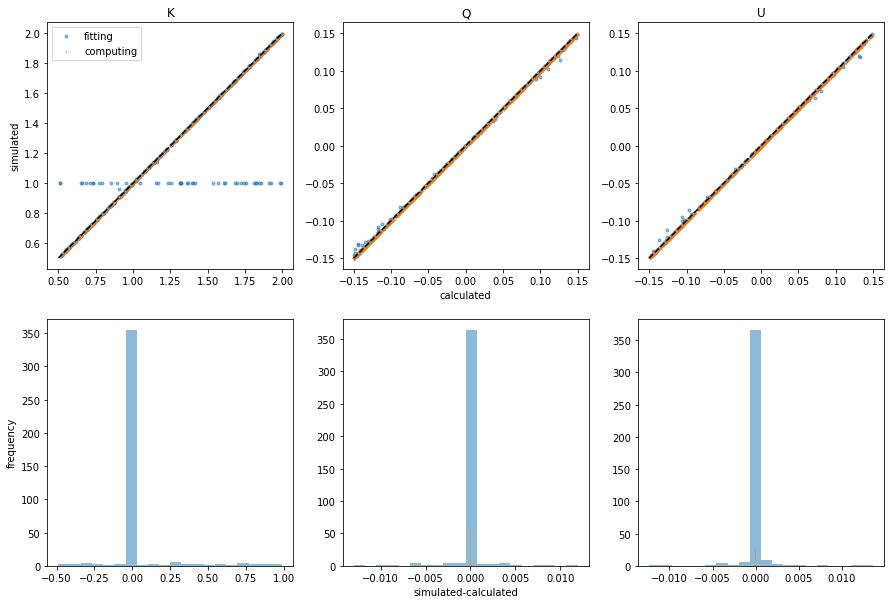

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(15, 10))

ax[0][0].plot(t['k'], t['k_fit'], 'o', ms=3, color='C0', alpha=0.5, label='fitting')
ax[0][0].plot(t['k'], t['k_calc'], '+', ms=3, color='C1', alpha=0.5, label='computing')
ax[0][0].plot([0.5, 2], [0.5, 2], 'k--')
ax[0][0].set_title('K')
ax[0][0].set_ylabel('simulated')
ax[0][0].legend()

ax[1][0].hist(t['k']-t['k_fit'], bins=20, color='C0', alpha=0.5)
ax[1][0].hist(t['k']-t['k_calc'], bins=20, color='C1', alpha=0.5)
ax[1][0].set_ylabel('frequency')

ax[0][1].plot(t['q'], t['q_fit'], 'o', ms=3, color='C0', alpha=0.5)
ax[0][1].plot(t['q'], t['q_fit_calc'], '+', ms=5, color='C1', alpha=0.5)
ax[0][1].plot([-0.15, 0.15], [-0.15, 0.15], 'k--')
ax[0][1].set_xlabel('calculated')
ax[0][1].set_title('Q')

ax[1][1].hist(t['q']-t['q_fit'], bins=20, color='C0', alpha=0.5)
ax[1][1].hist(t['q']-t['q_fit_calc'], bins=20, color='C1', alpha=0.5)
ax[1][1].set_xlabel('simulated-calculated')

ax[0][2].plot(t['u'], t['u_fit'], 'o', ms=3, color='C0', alpha=0.5)
ax[0][2].plot(t['u'], t['u_fit_calc'], '+', ms=5, color='C1', alpha=0.5)
ax[0][2].plot([-0.15, 0.15], [-0.15, 0.15], 'k--')
ax[0][2].set_title('U')

ax[1][2].hist(t['u']-t['u_fit'], bins=20, color='C0', alpha=0.5)
ax[1][2].hist(t['u']-t['u_fit_calc'], bins=20, color='C1', alpha=0.5)

plt.show()

## Quarter-Wave

With quarter-wave retarder, the graphic is not simmetric like half-wave. The term $\cos^2 2\Psi_i$ is always positive. So, compute the normalization by the vertical mean will get wrong results. Let's simulate the effect of $k$ in the graphs.

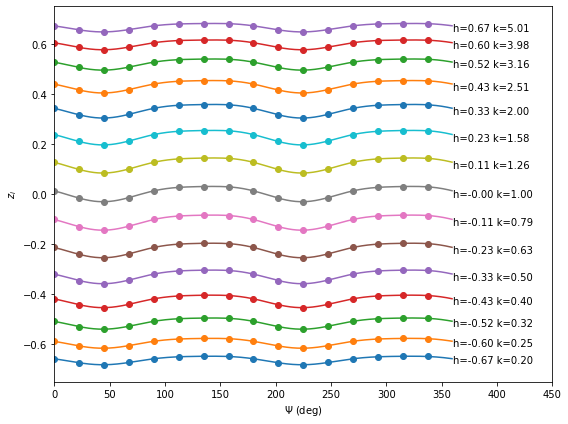

In [ ]:
f = 1e5
pos = np.radians(np.arange(0, 360, 22.5)*units.degree).value
line = np.arange(0, 360, 0.5)*units.degree

q = 0.0130
u = -0.0021
v = 0.03044

t = Table(names=['k', 'q_fit', 'u_fit', 'v_fit', 'h_fit'],
          dtype=['f4', 'f4', 'f4', 'f4', 'f4'])

plt.figure(figsize=(8, 6))
for i, kexp in enumerate(np.arange(-0.7, 0.8, 0.1)):
    k = 10**kexp
    fo, fe = get_flux_oe(f, pos, k, q, u, v)
    zi = (fo - fe)/(fo + fe)
    fitter = fitting.LevMarLSQFitter()
    mod_fit = fitter(QuarterWaveModel()+ConstModel(), pos, zi)
    t.add_row([k, *mod_fit.parameters])
    plt.plot(line, mod_fit(line), '-', color=f'C{i}')
    plt.plot(np.degrees(pos), zi, 'o', color=f'C{i}')
    h = mod_fit.parameters[-1]
    plt.annotate(f'h={h:.2f} k={k:.2f}', (360, h), va='center')

plt.xlim(0, 450)
plt.xlabel(r'$\Psi$ (deg)')
plt.ylabel(r'$z_i$')
plt.tight_layout()
plt.show()

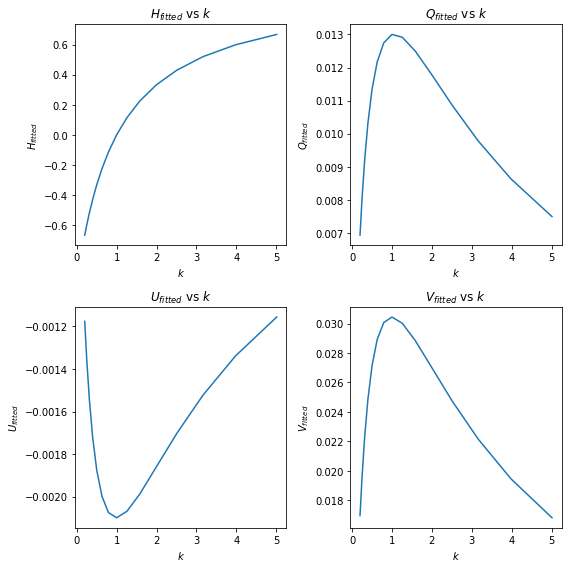

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(8, 8))

ax[0][0].plot(t['k'], t['h_fit'])
ax[0][0].set_title(r'$H_{fitted}$ vs $k$')
ax[0][0].set_xlabel(r'$k$')
ax[0][0].set_ylabel(r'$H_{fitted}$')

ax[0][1].plot(t['k'], t['q_fit'])
ax[0][1].set_title(r'$Q_{fitted}$ vs $k$')
ax[0][1].set_xlabel(r'$k$')
ax[0][1].set_ylabel(r'$Q_{fitted}$')

ax[1][0].plot(t['k'], t['u_fit'])
ax[1][0].set_title(r'$U_{fitted}$ vs $k$')
ax[1][0].set_xlabel(r'$k$')
ax[1][0].set_ylabel(r'$U_{fitted}$')

ax[1][1].plot(t['k'], t['v_fit'])
ax[1][1].set_title(r'$V_{fitted}$ vs $k$')
ax[1][1].set_xlabel(r'$k$')
ax[1][1].set_ylabel(r'$V_{fitted}$')

plt.tight_layout()
plt.show()

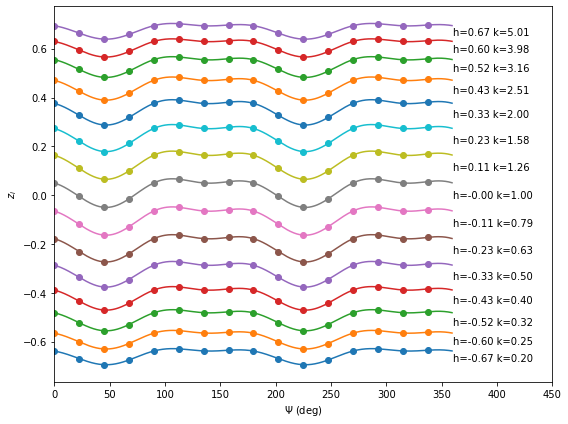

In [ ]:
# Again, with fake values
f = 1e5
pos = np.radians(np.arange(0, 360, 22.5)*units.degree).value
line = np.arange(0, 360, 0.5)*units.degree

q = 0.05
u = 0.01
v = 0.05

t = Table(names=['k', 'q_fit', 'u_fit', 'v_fit', 'h_fit'],
          dtype=['f4', 'f4', 'f4', 'f4', 'f4'])

plt.figure(figsize=(8, 6))
for i, kexp in enumerate(np.arange(-0.7, 0.8, 0.1)):
    k = 10**kexp
    fo, fe = get_flux_oe(f, pos, k, q, u, v)
    zi = (fo - fe)/(fo + fe)
    fitter = fitting.LevMarLSQFitter()
    mod_fit = fitter(QuarterWaveModel()+ConstModel(), pos, zi)
    t.add_row([k, *mod_fit.parameters])
    plt.plot(line, mod_fit(line), '-', color=f'C{i}')
    plt.plot(np.degrees(pos), zi, 'o', color=f'C{i}')
    h = mod_fit.parameters[-1]
    plt.annotate(f'h={h:.2f} k={k:.2f}', (360, h), va='center')

plt.xlim(0, 450)
plt.xlabel(r'$\Psi$ (deg)')
plt.ylabel(r'$z_i$')
plt.tight_layout()
plt.show()

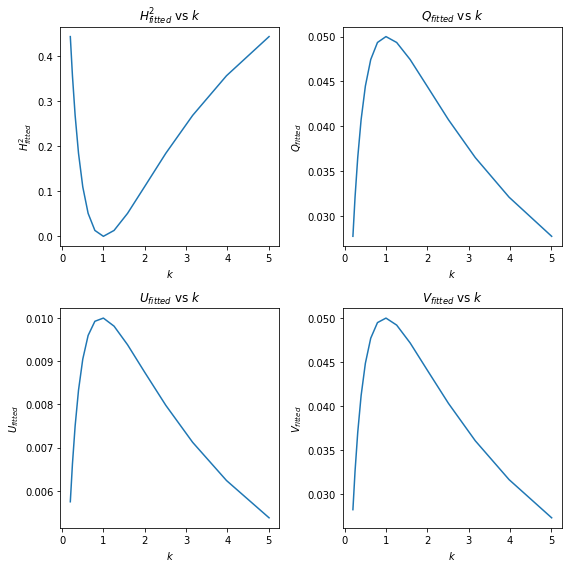

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(8, 8))

ax[0][0].plot(t['k'], t['h_fit']**2)
ax[0][0].set_title(r'$H_{fitted}^2$ vs $k$')
ax[0][0].set_xlabel(r'$k$')
ax[0][0].set_ylabel(r'$H_{fitted}^2$')

ax[0][1].plot(t['k'], t['q_fit'])
ax[0][1].set_title(r'$Q_{fitted}$ vs $k$')
ax[0][1].set_xlabel(r'$k$')
ax[0][1].set_ylabel(r'$Q_{fitted}$')

ax[1][0].plot(t['k'], t['u_fit'])
ax[1][0].set_title(r'$U_{fitted}$ vs $k$')
ax[1][0].set_xlabel(r'$k$')
ax[1][0].set_ylabel(r'$U_{fitted}$')

ax[1][1].plot(t['k'], t['v_fit'])
ax[1][1].set_title(r'$V_{fitted}$ vs $k$')
ax[1][1].set_xlabel(r'$k$')
ax[1][1].set_ylabel(r'$V_{fitted}$')

plt.tight_layout()
plt.show()